In [1]:
#%pip install torch

In [2]:
#import torch

#print(torch.__version__)

In [3]:
import numpy as np
import pandas as pd 
import torch 
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_auc_score
torch.manual_seed(0)

In [4]:
# --- file ---
FILE = "data/POWER_Point_Daily_19810101_20251231_008d50N_004d55E_LST.csv"
SKIP = 13        # header lines in the NASA POWER file before the column names

# --- dry day and dry spell ---
DRY_MM = 1.0
D = 8       # damaging dry spell = 8 or more consecutive dry days
H = 7       # predict within the next 7 days
WINDOW = 14      # days of history the LSTM sees

# --- onset of the rains (Sivakumar style, counted from 1 March for Ilorin) ---
ONSET_START_DOY = 60     # start looking from 1 March
ONSET_DAYS = 3           # rain is added up over this many consecutive days
ONSET_MM = 20            # ...and must reach at least this many mm
ONSET_MAX_DRY = 7        # no dry spell longer than this many days...
ONSET_LOOKAHEAD = 30     # ...in the following this many days

# --- model inputs ---
COLS = ["PRECTOTCORR", "RH2M", "T2M_MAX", "T2M_MIN", "T2M_RANGE", "sin_doy", "cos_doy"]

# --- split: train on the past, test on the future ---
TRAIN_END_YEAR = 2006
VAL_END_YEAR = 2012

In [5]:
df = pd.read_csv(FILE, skiprows=SKIP)
df["date"] = pd.to_datetime(df["YEAR"].astype(str) + "-01-01") + pd.to_timedelta(df["DOY"] - 1, unit="D")
df = df.set_index("date").replace(-999, np.nan)
n = len(df)

print("rows:", n, "(expect 16436)")
print("dates:", df.index.min().date(), "to", df.index.max().date())
print("missing values:", int(df.isna().sum().sum()))
df.head()

rows: 16436 (expect 16436)
dates: 1981-01-01 to 2025-12-31
missing values: 0


,YEAR,DOY,PRECTOTCORR,RH2M,T2M_MAX,T2M_MIN,T2M_RANGE
date,,,,,,,
1981-01-01,1981,1,0.00,64.93,30.83,18.85,11.98
1981-01-02,1981,2,0.00,58.68,29.59,17.05,12.54
1981-01-03,1981,3,0.03,65.40,30.16,16.45,13.71
1981-01-04,1981,4,0.14,71.89,29.13,18.06,11.07
1981-01-05,1981,5,0.00,66.86,29.11,15.32,13.79


In [6]:
def find_onset(year_df):
    rain = year_df["PRECTOTCORR"].values
    doy = year_df["DOY"].values
    for i in range(len(rain) - ONSET_DAYS - ONSET_LOOKAHEAD):
        if doy[i] < ONSET_START_DOY:
            continue
        wet_enough = rain[i : i + ONSET_DAYS].sum() >= ONSET_MM
        after = rain[i + ONSET_DAYS : i + ONSET_DAYS + ONSET_LOOKAHEAD]
        longest, run = 0, 0
        for r in after:
            run = run + 1 if r < DRY_MM else 0
            longest = max(longest, run)
        if wet_enough and longest <= ONSET_MAX_DRY:
            return doy[i]
    return np.nan

onset_doy = df.groupby("YEAR")[["PRECTOTCORR", "DOY"]].apply(find_onset)
onset_dates = pd.to_datetime("2001-01-01") + pd.to_timedelta(onset_doy - 1, unit="D")

print("years with no onset found:", int(onset_doy.isna().sum()))
print("median onset:", onset_dates.median().strftime("%d %b"))
print("earliest:", onset_dates.min().strftime("%d %b"), "| latest:", onset_dates.max().strftime("%d %b"))

onset_doy.describe()

years with no onset found: 0
median onset: 17 Apr
earliest: 20 Mar | latest: 09 Jun


count     45.000000
mean     112.800000
std       21.508561
min       79.000000
25%       98.000000
50%      107.000000
75%      126.000000
max      160.000000
dtype: float64

In [7]:
#%conda install matplotlib -y

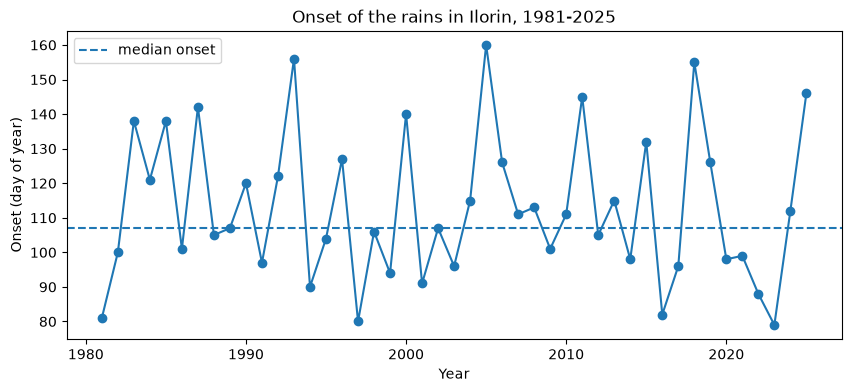

In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))
plt.plot(onset_doy.index, onset_doy.values, marker="o")
plt.axhline(onset_doy.median(), linestyle="--", label="median onset")
plt.xlabel("Year"); plt.ylabel("Onset (day of year)"); plt.legend()
plt.title("Onset of the rains in Ilorin, 1981-2025")
plt.show()

In [9]:
dry = (df["PRECTOTCORR"] < DRY_MM).values.astype(int)

run = np.zeros(n, dtype=int)
for i in range(n - 1, -1, -1):
    if dry[i]:
        run[i] = (run[i + 1] if i + 1 < n else 0) + 1
spell = (run >= D).astype(int)

y = np.full(n, np.nan)
for i in range(n - H):
    y[i] = spell[i + 1 : i + 1 + H].max()

print("share of days followed by a dry spell:", round(float(np.nanmean(y)), 3))

share of days followed by a dry spell: 0.341


In [10]:
f = df.copy()

# new feature 1: consecutive dry days up to today
dry_today = (df["PRECTOTCORR"] < DRY_MM).values.astype(int)
dry_days = np.zeros(n)
for i in range(n):
    if dry_today[i]:
        dry_days[i] = (dry_days[i - 1] if i > 0 else 0) + 1
f["dry_days"] = dry_days

# new feature 2: total rain in the last 7 days (from the raw rainfall)
f["rain_7d"] = df["PRECTOTCORR"].rolling(7, min_periods=1).sum()

# existing features
f["PRECTOTCORR"] = np.log1p(f["PRECTOTCORR"])
f["sin_doy"] = np.sin(2 * np.pi * df["DOY"] / 365.25)
f["cos_doy"] = np.cos(2 * np.pi * df["DOY"] / 365.25)
f = f[COLS]

years = df.index.year.values
train_rows = years <= TRAIN_END_YEAR

X_all = (
    (f - f[train_rows].mean()) / f[train_rows].std()
).values.astype("float32")
idx = [i for i in range(WINDOW - 1, n - H) if 3 <= df.index[i].month <= 10]
Xw = np.stack([X_all[i - WINDOW + 1 : i + 1] for i in idx])
yw = np.array([y[i] for i in idx], dtype="float32")

valid = ~np.isnan(yw)
Xw = Xw[valid]
yw = yw[valid]
idx = np.array(idx)[valid]

window_years = years[idx]

tr = window_years <= TRAIN_END_YEAR
val = (window_years > TRAIN_END_YEAR) & (window_years <= VAL_END_YEAR)
te = window_years > VAL_END_YEAR

print("windows:", Xw.shape)
print("train examples:", int(tr.sum()), "| val examples:", int(val.sum()), "| test examples:", int(te.sum()))
print("dry-spell share: train", round(float(yw[tr].mean()), 2), "| test", round(float(yw[te].mean()), 2))
print("any missing values in inputs:", bool(np.isnan(Xw).any()))

windows: (11025, 14, 7)
train examples: 6370 | val examples: 1470 | test examples: 3185
dry-spell share: train 0.1 | test 0.06
any missing values in inputs: False


In [11]:
class RainLSTM(nn.Module):
    def __init__(self, n_features, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, batch_first=True)
        self.out = nn.Linear(hidden, 1)

    def forward(self, x):
        _, (h, _) = self.lstm(x)
        return self.out(h[-1]).squeeze(-1)

In [12]:
def make_loader(mask, shuffle):
    ds = TensorDataset(
        torch.tensor(Xw[mask], dtype=torch.float32),
        torch.tensor(yw[mask], dtype=torch.float32)
    )
    return DataLoader(ds, batch_size=64, shuffle=shuffle)

train_dl = make_loader(tr, True)
val_dl = make_loader(val, False)
test_dl = make_loader(te, False)

# FIXED: negatives divided by positives
n_pos = yw[tr].sum()
n_neg = len(yw[tr]) - n_pos
pos_weight = torch.tensor([n_neg / n_pos], dtype=torch.float32)
print("pos_weight:", round(float(pos_weight), 2))

loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

pos_weight: 8.85


In [13]:
print("Training labels:")
print(pd.Series(yw[tr]).value_counts())

print("\nValidation labels:")
print(pd.Series(yw[val]).value_counts())

print("\nTesting labels:")
print(pd.Series(yw[te]).value_counts())

Training labels:
0.0    5723
1.0     647
Name: count, dtype: int64

Validation labels:
0.0    1352
1.0     118
Name: count, dtype: int64

Testing labels:
0.0    2981
1.0     204
Name: count, dtype: int64


In [14]:
torch.manual_seed(0)
model = RainLSTM(len(COLS))
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

best_val_auc = 0
best_model_state = None

for epoch in range(6):
    model.train()

    for xb, yb in train_dl:
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        opt.step()

    model.eval()

    with torch.no_grad():
        val_p = torch.cat([
            torch.sigmoid(model(xb)) for xb, _ in val_dl
        ]).numpy()

    val_auc = roc_auc_score(yw[val], val_p)

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_model_state = {
            k: v.detach().clone()
            for k, v in model.state_dict().items()
        }

    print(f"Epoch {epoch + 1} | Validation AUC: {val_auc:.3f}")

model.load_state_dict(best_model_state)

print("Best validation AUC:", round(best_val_auc, 3))

Epoch 1 | Validation AUC: 0.908
Epoch 2 | Validation AUC: 0.915
Epoch 3 | Validation AUC: 0.923
Epoch 4 | Validation AUC: 0.929
Epoch 5 | Validation AUC: 0.937
Epoch 6 | Validation AUC: 0.925
Best validation AUC: 0.937


In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score

model.eval()

with torch.no_grad():
    val_p = torch.cat([
        torch.sigmoid(model(xb)) for xb, _ in val_dl
    ]).numpy()

thresholds = [0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]

best_f1 = -1
BEST_THRESHOLD = 0.5

for threshold in thresholds:
    val_predictions = (val_p >= threshold).astype(int)

    precision = precision_score(yw[val], val_predictions, zero_division=0)
    recall = recall_score(yw[val], val_predictions, zero_division=0)
    f1 = f1_score(yw[val], val_predictions, zero_division=0)

    if f1 > best_f1:
        best_f1 = f1
        BEST_THRESHOLD = threshold

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

BEST_THRESHOLD = 0.70
print("\nFinal threshold chosen (recall-leaning):", BEST_THRESHOLD)

Threshold: 0.50 | Precision: 0.313 | Recall: 0.915 | F1: 0.467
Threshold: 0.60 | Precision: 0.358 | Recall: 0.805 | F1: 0.496
Threshold: 0.70 | Precision: 0.412 | Recall: 0.712 | F1: 0.522
Threshold: 0.75 | Precision: 0.478 | Recall: 0.653 | F1: 0.552
Threshold: 0.80 | Precision: 0.554 | Recall: 0.610 | F1: 0.581
Threshold: 0.85 | Precision: 0.593 | Recall: 0.458 | F1: 0.517
Threshold: 0.90 | Precision: 0.793 | Recall: 0.195 | F1: 0.313
Threshold: 0.95 | Precision: 0.000 | Recall: 0.000 | F1: 0.000

Final threshold chosen (recall-leaning): 0.7


In [16]:
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

model.eval()

with torch.no_grad():
    test_p = torch.cat([
        torch.sigmoid(model(xb)) for xb, _ in test_dl
    ]).numpy()

test_predictions = (test_p >= BEST_THRESHOLD).astype(int)

print("Threshold used:", BEST_THRESHOLD)
print("Test AUC:", round(roc_auc_score(yw[te], test_p), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(yw[te], test_predictions))

print("\nClassification Report:")
print(classification_report(yw[te], test_predictions, zero_division=0))

Threshold used: 0.7
Test AUC: 0.823

Confusion Matrix:
[[2649  332]
 [  78  126]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.97      0.89      0.93      2981
         1.0       0.28      0.62      0.38       204

    accuracy                           0.87      3185
   macro avg       0.62      0.75      0.65      3185
weighted avg       0.93      0.87      0.89      3185



In [17]:
test_years = years[idx][te]

results = []

for year in np.unique(test_years):
    mask = test_years == year

    actual = yw[te][mask]
    predicted_prob = test_p[mask]
    predicted = (predicted_prob >= BEST_THRESHOLD).astype(int)

    if len(np.unique(actual)) == 2:
        auc = roc_auc_score(actual, predicted_prob)
    else:
        auc = np.nan

    results.append({
        "Year": year,
        "Examples": len(actual),
        "Actual dry spells": int(actual.sum()),
        "AUC": auc,
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1": f1_score(actual, predicted, zero_division=0)
    })

yearly_results = pd.DataFrame(results)

print(yearly_results.round(3).to_string(index=False))

 Year  Examples  Actual dry spells   AUC  Precision  Recall    F1
 2013       245                 18 0.551      0.200   0.444 0.276
 2014       245                 12 0.408      0.091   0.250 0.133
 2015       245                 23 0.828      0.146   0.261 0.188
 2016       245                 12 0.992      0.343   1.000 0.511
 2017       245                 29 0.943      0.524   0.759 0.620
 2018       245                 11 0.868      0.167   0.545 0.255
 2019       245                 15 0.993      0.538   0.933 0.683
 2020       245                 26 0.982      0.686   0.923 0.787
 2021       245                  9 0.840      0.081   0.333 0.130
 2022       245                 13 0.987      0.361   1.000 0.531
 2023       245                  0   NaN      0.000   0.000 0.000
 2024       245                 36 0.668      0.484   0.417 0.448
 2025       245                  0   NaN      0.000   0.000 0.000


In [18]:
yearly_counts = []

for year in np.unique(test_years):
    mask = test_years == year

    actual = yw[te][mask]
    predicted = (test_p[mask] >= BEST_THRESHOLD).astype(int)

    yearly_counts.append({
        "Year": year,
        "Actual events": int(actual.sum()),
        "Predicted events": int(predicted.sum())
    })

print(pd.DataFrame(yearly_counts).to_string(index=False))

 Year  Actual events  Predicted events
 2013             18                40
 2014             12                33
 2015             23                41
 2016             12                35
 2017             29                42
 2018             11                36
 2019             15                26
 2020             26                35
 2021              9                37
 2022             13                36
 2023              0                31
 2024             36                31
 2025              0                35


In [19]:
def predict_dry_spell(days):
    """days = a table of 14 days with the columns:
    PRECTOTCORR, RH2M, T2M_MAX, T2M_MIN, T2M_RANGE, DOY"""
    x = days.copy()

    # same preparation steps as the real data
    x["PRECTOTCORR"] = np.log1p(x["PRECTOTCORR"])
    x["sin_doy"] = np.sin(2 * np.pi * x["DOY"] / 365.25)
    x["cos_doy"] = np.cos(2 * np.pi * x["DOY"] / 365.25)
    x = x[COLS]

    # scale using the TRAINING mean and std (same as before)
    x = (x - f[train_rows].mean()) / f[train_rows].std()

    # shape the model expects: (1 window, 14 days, features)
    xt = torch.tensor(x.values.astype("float32")).unsqueeze(0)

    model.eval()
    with torch.no_grad():
        score = torch.sigmoid(model(xt)).item()
    return score


def make_days(rain, rh, tmax, tmin, start_doy):
    return pd.DataFrame({
        "PRECTOTCORR": rain,
        "RH2M": rh,
        "T2M_MAX": tmax,
        "T2M_MIN": tmin,
        "T2M_RANGE": np.array(tmax) - np.array(tmin),
        "DOY": range(start_doy, start_doy + 14),
    })


# Dummy case 1: 14 dry, hot days (early August)
dry_days_df = make_days(
    rain=[0, 0, 0.2, 0, 0, 0, 0, 0.1, 0, 0, 0, 0, 0, 0],
    rh=[58, 56, 60, 55, 54, 57, 53, 52, 55, 54, 53, 52, 51, 50],
    tmax=[34, 34.5, 33.8, 35, 35.2, 34.8, 35.5, 35.9, 35.4, 35.6, 36, 36.2, 35.8, 36.1],
    tmin=[22.5, 22, 22.8, 22.1, 21.9, 22.3, 21.8, 21.5, 22, 21.7, 21.6, 21.3, 21.5, 21.2],
    start_doy=215,
)

# Dummy case 2: 14 wet, humid days (early June)
wet_days_df = make_days(
    rain=[12, 25, 8, 0, 30, 15, 5, 22, 18, 10, 0, 28, 14, 9],
    rh=[88, 90, 86, 80, 91, 89, 85, 90, 88, 87, 82, 91, 89, 86],
    tmax=[29, 28.5, 29.5, 31, 28, 29, 30, 28.5, 29, 29.5, 30.5, 28, 29, 29.5],
    tmin=[22, 21.8, 22.2, 22.5, 21.5, 22, 22.1, 21.7, 22, 22.3, 22.4, 21.6, 21.9, 22],
    start_doy=150,
)

# Dummy case 3: rain first, then it dries out (late July)
drying_df = make_days(
    rain=[15, 20, 8, 12, 5, 2, 0, 0, 0, 0.1, 0, 0, 0, 0],
    rh=[85, 88, 84, 82, 78, 72, 66, 62, 60, 58, 57, 55, 54, 53],
    tmax=[29, 29, 30, 30, 31, 32, 33, 34, 34.5, 35, 35.2, 35.5, 35.8, 36],
    tmin=[22, 22, 22.3, 22.2, 22, 21.8, 21.7, 21.6, 21.5, 21.4, 21.3, 21.2, 21.2, 21.1],
    start_doy=200,
)

THRESHOLD = 0.70

for name, days in [("Dry and hot", dry_days_df),
                   ("Wet and humid", wet_days_df),
                   ("Rain then drying out", drying_df)]:
    score = predict_dry_spell(days)
    decision = "WARNING: dry spell likely" if score >= THRESHOLD else "No warning"
    print(f"{name:22s} | score: {score:.2f} | {decision}")

Dry and hot            | score: 0.19 | No warning
Wet and humid          | score: 0.00 | No warning
Rain then drying out   | score: 0.02 | No warning


In [20]:
test_dates = df.index[idx][te]

highest = test_p.argmax()
lowest = test_p.argmin()

for label, i in [("Highest-risk test day", highest),
                 ("Lowest-risk test day", lowest)]:
    actual = "Yes" if yw[te][i] == 1 else "No"
    decision = "WARNING" if test_p[i] >= 0.70 else "No warning"
    print(f"{label}: {test_dates[i].date()} | score: {test_p[i]:.2f} | "
          f"{decision} | dry spell actually followed: {actual}")

# one more dummy case: March, when dry spells are common
march_df = make_days(
    rain=[0, 0, 0, 0, 0, 0.3, 0, 0, 0, 0, 0, 0, 0.1, 0],
    rh=[48, 45, 50, 47, 46, 52, 44, 43, 45, 44, 42, 43, 46, 41],
    tmax=[35, 35.5, 36, 35.8, 36.2, 35, 36.5, 36.8, 37, 36.6, 37.2, 37, 36.8, 37.3],
    tmin=[23, 23.5, 24, 23.8, 24.2, 23.6, 24.5, 24.4, 24.8, 24.6, 25, 24.7, 24.5, 25],
    start_doy=65,
)
score = predict_dry_spell(march_df)
print(f"Dry March week        | score: {score:.2f} | "
      f"{'WARNING' if score >= 0.70 else 'No warning'}")

Highest-risk test day: 2020-10-31 | score: 0.95 | WARNING | dry spell actually followed: Yes
Lowest-risk test day: 2021-08-09 | score: 0.00 | No warning | dry spell actually followed: No
Dry March week        | score: 0.79 | WARNING


In [22]:
import os

torch.save(model.state_dict(), "Ilorin_rain_lstm.pt")

print("Saved in folder:", os.getcwd())
print("Files there:", [f for f in os.listdir() if f.endswith((".pt", ".ipynb", ".txt"))])

Saved in folder: C:\Users\SALAMAH\Hackathon Project
Files there: ['Ilorin-rainfall.ipynb', 'Ilorin_rain_lstm.pt', 'POWER.ipynb', 'Untitled.ipynb']


In [23]:
stats = pd.DataFrame({
    "mean": f[train_rows].mean(),
    "std": f[train_rows].std()
})
stats.to_csv("scaling_stats.csv")
print(stats)

                  mean        std
PRECTOTCORR   1.000530   0.934870
RH2M         73.878072  14.690241
T2M_MAX      30.985686   2.938434
T2M_MIN      20.959247   2.149722
T2M_RANGE    10.026439   3.592664
sin_doy       0.000004   0.707163
cos_doy      -0.000053   0.707125
